### Data Exploration

In [23]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Bulletproof (works no matter where you run from):
from pathlib import Path

In [24]:
# load the dataset
data_path = next(
   (
      path
      for path in [
         Path.cwd() / "data" / "Stars.csv",
         Path.cwd() / "src" / "data" / "Stars.csv",
         Path.cwd().parent / "data" / "Stars.csv",
         Path.cwd().parent / "src" / "data" / "Stars.csv",
      ]
      if path.exists()
   ),
   None
)

if data_path is None:
   raise FileNotFoundError(
      "Could not find 'Stars.csv'. Make sure the dataset exists in one of the expected locations."
   )
df = pd.read_csv(data_path)
df

,Temperature,L,R,A_M,Color,Spectral_Class,Type
0,3068,0.002400,0.1700,16.12,Red,M,0
1,3042,0.000500,0.1542,16.60,Red,M,0
2,2600,0.000300,0.1020,18.70,Red,M,0
3,2800,0.000200,0.1600,16.65,Red,M,0
4,1939,0.000138,0.1030,20.06,Red,M,0
...,...,...,...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93,Blue,O,5
236,30839,834042.000000,1194.0000,-10.63,Blue,O,5
237,8829,537493.000000,1423.0000,-10.73,White,A,5
238,9235,404940.000000,1112.0000,-11.23,White,A,5


In [25]:
# compute summary statistics for the dataset
df.describe()

,Temperature,L,R,A_M,Type
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,40000.000000,849420.000000,1948.500000,20.060000,5.000000


In [26]:
# check the data types of each column
df.dtypes

Temperature         int64
L                 float64
R                 float64
A_M               float64
Color                 str
Spectral_Class        str
Type                int64
dtype: object

In [28]:
# check if the data is skewed or not
df.select_dtypes(include='number').skew()   

# ~0 → roughly symmetric
# > 1 or < -1 → heavily skewed
# 0.5 to 1 → moderately skewed

Temperature    1.321568e+00
L              2.068069e+00
R              1.946800e+00
A_M           -1.215396e-01
Type           9.121079e-17
dtype: float64

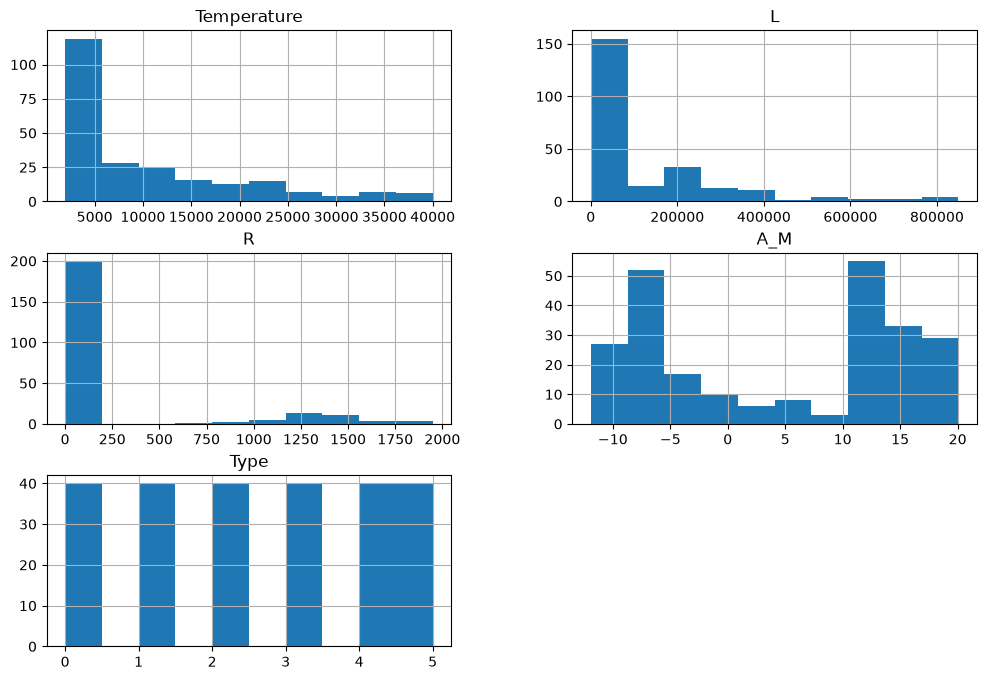

In [29]:
# visualize the distribution of numerical features
df.select_dtypes(include='number').hist(figsize=(12, 8))
plt.show()   

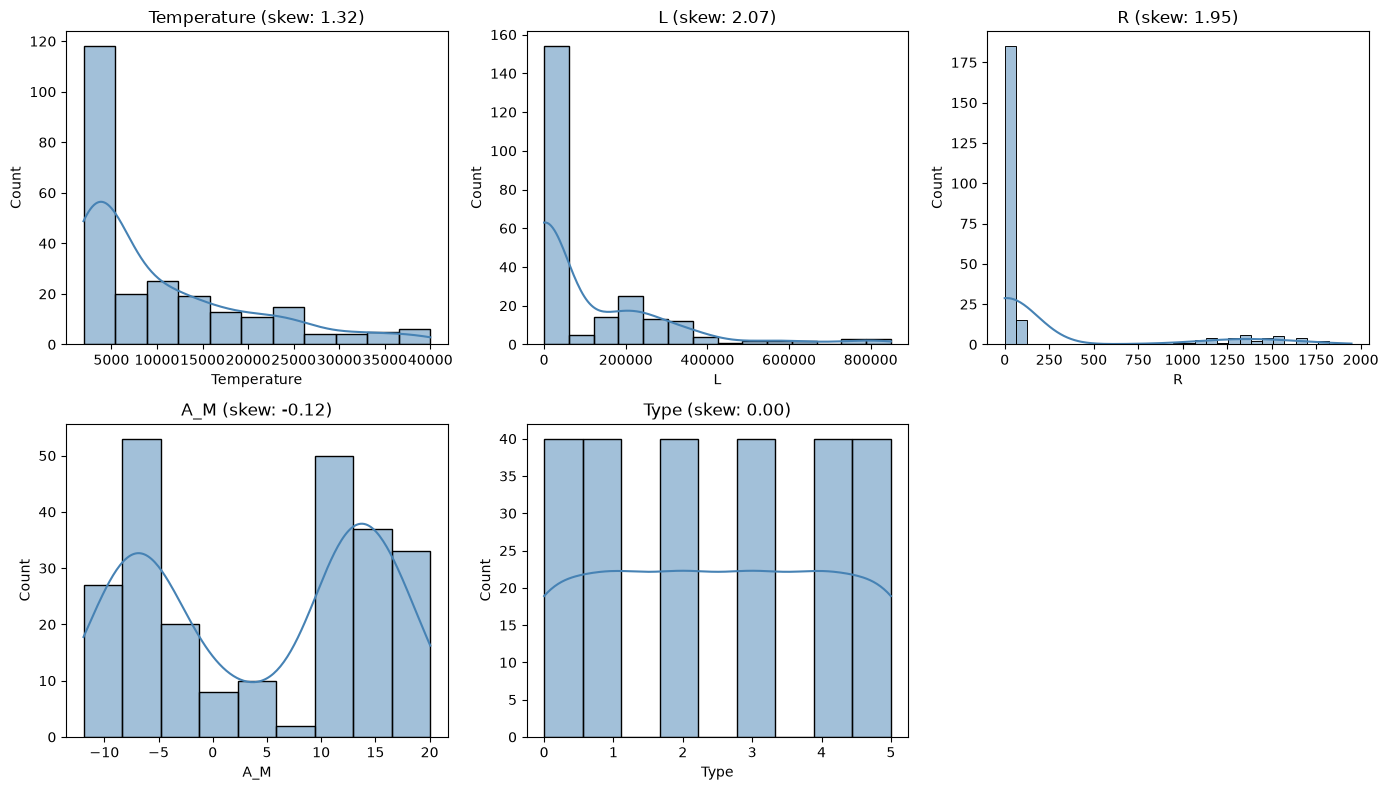

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

num_df = df.select_dtypes(include='number')
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(num_df.columns):
    sns.histplot(num_df[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f"{col} (skew: {num_df[col].skew():.2f})")

# Hide unused subplots
for j in range(len(num_df.columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()   

In [31]:
# identify unique values in color features
categorical_features = df.select_dtypes(include='object').columns

for col in categorical_features:
    unique_values = df[col].unique()
    print(f"Unique values in '{col}': {unique_values}")

Unique values in 'Color': <StringArray>
[               'Red',         'Blue White',              'White',
    'Yellowish White',         'Blue white', 'Pale yellow orange',
               'Blue',         'Blue-white',            'Whitish',
       'yellow-white',             'Orange',       'White-Yellow',
              'white',          'yellowish',          'Yellowish',
         'Orange-Red',         'Blue-White']
Length: 17, dtype: str
Unique values in 'Spectral_Class': <StringArray>
['M', 'B', 'A', 'F', 'O', 'K', 'G']
Length: 7, dtype: str


C:\Users\Samsung\AppData\Local\Temp\ipykernel_20868\2056940739.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include='object').columns


In [33]:
# check the counts of each unique value in the 'Spectral_class' column
df['Spectral_Class'].value_counts()   

Spectral_Class
M    111
B     46
O     40
A     19
F     17
K      6
G      1
Name: count, dtype: int64

In [27]:
# check if the data is balanced or imbalanced
df['Type'].value_counts()   

Type
0    40
1    40
2    40
3    40
4    40
5    40
Name: count, dtype: int64